<a href="https://colab.research.google.com/github/MuskanZehra5/QML_Project_Diabetic_Retinopathy/blob/main/DFPD_quantum_kernel_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum kernel clustering of fundus photographs (DFPD)
AI-61 QML project. Unsupervised: **no labels needed**.

Pipeline: photo -> 6 image-quality features -> scaled to angles -> 6-qubit ZZ feature map -> **quantum kernel** (compute-uncompute, fidelity between states) -> **kernel k-means** and **spectral clustering**.
Compared with classical k-means and RBF-kernel clustering on the same 6 features. Fair metric: **stability** (how much the clusters change when 20% of the photos are dropped), plus agreement with your quality labels if `labels.csv` exists.

Honest expectation: the quantum kernel will probably find similar clusters to the classical ones. Both outcomes are reportable.

In [1]:
!pip -q install qiskit
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os, hashlib, itertools, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import entropy as sp_entropy
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.decomposition import PCA, KernelPCA
from sklearn.metrics import silhouette_score, adjusted_rand_score as ARI, normalized_mutual_info_score as NMI
from sklearn.metrics.pairwise import rbf_kernel
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
warnings.filterwarnings("ignore")

DATA_DIR = "/content/drive/MyDrive/Eye Data"
WORK_DIR = "/content/drive/MyDrive/QML_labeling"
SEED = 7
K_RANGE = range(2, 7)
os.makedirs(WORK_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

In [13]:

if os.path.exists(DATA_DIR):
    print("Eye Data folder FOUND!")

    files = os.listdir(DATA_DIR)
    print("Total items:", len(files))
    print("\nFirst 10 items:")

    for file in files[:10]:
        print(file)
else:
    print("Eye Data folder NOT FOUND.")

Eye Data folder FOUND!
Total items: 6

First 10 items:
D:
color_001.jpg
52d67913-9f18-4e40-8c27-18115da63c49.jpg
dc8436f4-ee78-49ff-ac22-a5a967fc6677.jpg
74704315-9c6f-4117-b8f6-10e4b8c5ae81.jpg
f68ad973-44d3-4c3f-82e6-fbd3b0e271ab.jpg


In [14]:
## counting images

extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')

for root, dirs, files in os.walk(DATA_DIR):
    dirs[:] = [d for d in dirs if d != "System Volume Information"]

    images = [f for f in files if f.lower().endswith(extensions)]

    if images:
        print(f"\nFolder: {root}")
        print(f"Images: {len(images)}")


Folder: /content/drive/MyDrive/Eye Data
Images: 5

Folder: /content/drive/MyDrive/Eye Data/D:
Images: 5

Folder: /content/drive/MyDrive/Eye Data/D:/DATA
Images: 255


## 1. Load images (same image_id as the labeling toolkit)

In [16]:
inv_f = f"{WORK_DIR}/inventory.csv"
if os.path.exists(inv_f):
    inv = pd.read_csv(inv_f)[["image_id", "path"]]
else:
    EXT = {".jpg", ".jpeg", ".png"}
    paths = sorted(os.path.join(r, f) for r, _, fs in os.walk(DATA_DIR) for f in fs if os.path.splitext(f)[1].lower() in EXT)
    rows = [dict(path=p, sha=hashlib.sha256(open(p, "rb").read()).hexdigest()) for p in paths]
    inv = pd.DataFrame(rows).drop_duplicates("sha").reset_index(drop=True)
    inv["image_id"] = inv.sha.str[:10]; inv = inv[["image_id", "path"]]
print(len(inv), "images")

258 images


## 2. Six features per photo (green channel, which shows retinal detail best)

In [17]:
FEATS = ["log_laplacian_var", "mean_lum", "std_lum", "entropy", "fov_coverage", "edge_density"]

def features(path, side=512):
    im = np.array(Image.open(path).convert("RGB"))
    h, w = im.shape[:2]; s = side / max(h, w)
    g = cv2.resize(im[:, :, 1], (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    fov = g > 15 # retina field versus black background
    fov_cov = fov.mean()
    inner = cv2.erode(fov.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)   # ignore the rim
    if inner.sum() < 100: inner = fov if fov.sum() >= 100 else np.ones_like(fov)
    gf = g.astype(np.float32)
    lap = cv2.Laplacian(gf, cv2.CV_32F)[inner].var()
    v = gf[inner]
    hist, _ = np.histogram(v, bins=64, range=(0, 255)); ent = sp_entropy(hist + 1e-9, base=2)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    edges = cv2.Canny(clahe, 30, 90)[inner].mean() / 255.0
    return [np.log1p(lap), v.mean(), v.std(), ent, fov_cov, edges]

F = np.array([features(p) for p in inv.path])
feat = pd.DataFrame(F, columns=FEATS); feat.insert(0, "image_id", inv.image_id.values)
print(feat[FEATS].describe().round(2).to_string())

       log_laplacian_var  mean_lum  std_lum  entropy  fov_coverage  edge_density
count             258.00    258.00   258.00   258.00        258.00        258.00
mean                3.94    109.55    23.33     3.95          0.74          0.17
std                 1.74     39.94    15.18     0.58          0.07          0.09
min                 2.32     23.51     2.94     1.61          0.19          0.00
25%                 3.01     83.15    15.78     3.67          0.73          0.11
50%                 3.46    106.95    18.65     4.00          0.73          0.17
75%                 3.96    128.41    24.30     4.22          0.73          0.22
max                10.27    227.56    81.59     5.61          1.00          0.39


## 3. Scale to angles in [0, pi] (clip at the 5th and 95th percentile so outliers do not squash the rest)

In [18]:
lo, hi = np.percentile(F, 5, axis=0), np.percentile(F, 95, axis=0)
X = np.clip((F - lo) / (hi - lo + 1e-12), 0, 1) * np.pi

## 4. Quantum kernel
For photos x and y the feature map U(x) is a ZZ feature map on 6 qubits. The kernel is k(x,y) = |<0|U(y)^dagger U(x)|0>|^2, the probability that the compute-uncompute circuit returns all zeros.
We compute it exactly from statevectors. `alpha` stretches the angles: too large and all kernel values collapse towards 0 ("kernel concentration"), too small and all photos look alike.

In [19]:
def quantum_kernel(Xa, reps=2, alpha=1.0, ent="linear"):
    fm = zz_feature_map(Xa.shape[1], reps=reps, entanglement=ent)
    S = np.array([Statevector(fm.assign_parameters(alpha * x)).data for x in Xa])
    K = np.abs(S.conj() @ S.T) ** 2
    return (K + K.T) / 2

def shot_kernel(K, shots, rng):
    # measuring the compute-uncompute circuit `shots` times: the all-zero count is Binomial(shots, k)
    n = len(K); Ks = np.eye(n)
    iu = np.triu_indices(n, 1)
    Ks[iu] = rng.binomial(shots, np.clip(K[iu], 0, 1)) / shots
    return Ks + Ks.T - np.eye(n)

def dist_from_kernel(K):
    d = np.diag(K)[:, None] + np.diag(K)[None, :] - 2 * K
    return np.sqrt(np.clip(d, 0, None))

## 5. Clustering methods (all work from a kernel matrix)

In [20]:
def kernel_kmeans(K, k, n_init=10, iters=100, seed=0):
    n = len(K); r = np.random.default_rng(seed); best, best_in = None, np.inf
    for _ in range(n_init):
        lab = r.integers(0, k, n)
        for _ in range(iters):
            D = np.zeros((n, k))
            for c in range(k):
                m = lab == c
                if m.sum() == 0: D[:, c] = np.inf; continue
                D[:, c] = np.diag(K) - 2 * K[:, m].mean(1) + K[np.ix_(m, m)].mean()
            new = D.argmin(1)
            if (new == lab).all(): break
            lab = new
        inertia = D[np.arange(n), lab].sum()
        if inertia < best_in: best, best_in = lab.copy(), inertia
    return best

def spectral(K, k, seed=0):
    return SpectralClustering(k, affinity="precomputed", random_state=seed, assign_labels="kmeans").fit_predict(K)

def kmeans_feat(Xa, k, seed=0):
    return KMeans(k, n_init=10, random_state=seed).fit_predict(Xa)

def stability(fit, n, frac=0.8, draws=20, seed=0, k=None):
    # cluster the full set, then cluster random 80% subsets; ARI between them on the shared photos
    r = np.random.default_rng(seed); full = fit(np.arange(n)); sc = []
    for _ in range(draws):
        idx = np.sort(r.choice(n, int(frac * n), replace=False))
        sc.append(ARI(full[idx], fit(idx)))
    return np.mean(sc), np.std(sc), full

## 6. Choose the kernel stretch `alpha` and depth (no labels used)

In [21]:
rows = []
for reps, alpha in itertools.product([1, 2], [0.25, 0.5, 1.0, 2.0]):
    K = quantum_kernel(X, reps=reps, alpha=alpha)
    off = K[np.triu_indices(len(K), 1)]
    best = None
    for k in K_RANGE:
        lab = spectral(K, k)
        if len(set(lab)) < 2: continue
        sil = silhouette_score(dist_from_kernel(K), lab, metric="precomputed")
        if best is None or sil > best[1]: best = (k, sil)
    stab, _, _ = stability(lambda i: spectral(K[np.ix_(i, i)], best[0]), len(K), draws=8)
    rows.append(dict(reps=reps, alpha=alpha, kernel_mean=off.mean(), kernel_std=off.std(), best_k=best[0], silhouette=best[1], stability=stab))
grid = pd.DataFrame(rows).round(3); print(grid.to_string(index=False))
pick = grid.sort_values("stability", ascending=False).iloc[0]
REPS, ALPHA, K_Q = int(pick.reps), float(pick.alpha), int(pick.best_k)
print(f"\nchosen: reps={REPS}, alpha={ALPHA}, k={K_Q}  (highest stability; kernel_std near 0 would mean concentration)")

 reps  alpha  kernel_mean  kernel_std  best_k  silhouette  stability
    1   0.25        0.150       0.227       6       0.170      0.771
    1   0.50        0.045       0.121       6       0.083      0.659
    1   1.00        0.024       0.071       6       0.040      0.496
    1   2.00        0.018       0.041       6       0.015      0.335
    2   0.25        0.099       0.179       6       0.139      0.632
    2   0.50        0.037       0.091       6       0.065      0.691
    2   1.00        0.026       0.062       6       0.033      0.538
    2   2.00        0.023       0.038       6       0.014      0.633

chosen: reps=1, alpha=0.25, k=6  (highest stability; kernel_std near 0 would mean concentration)


## 7. Final comparison: quantum vs classical (same photos, same number of clusters)

In [22]:
K_FIXED = K_Q
Kq = quantum_kernel(X, reps=REPS, alpha=ALPHA)
d_med = np.median(np.linalg.norm(X[:, None] - X[None], axis=2)[np.triu_indices(len(X), 1)])
Kc = rbf_kernel(X, gamma=1.0 / (2 * d_med ** 2))

methods = {
    "Quantum kernel + spectral":     lambda i: spectral(Kq[np.ix_(i, i)], K_FIXED),
    "Quantum kernel + kernel k-means": lambda i: kernel_kmeans(Kq[np.ix_(i, i)], K_FIXED, n_init=5),
    "RBF kernel + spectral":         lambda i: spectral(Kc[np.ix_(i, i)], K_FIXED),
    "RBF kernel + kernel k-means":   lambda i: kernel_kmeans(Kc[np.ix_(i, i)], K_FIXED, n_init=5),
    "Plain k-means (features)":      lambda i: kmeans_feat(X[i], K_FIXED),
}
assign, res = {}, []
for name, fit in methods.items():
    m, s, full = stability(fit, len(X), draws=20)
    assign[name] = full; res.append(dict(method=name, stability_ARI=round(m, 3), sd=round(s, 3), cluster_sizes=np.bincount(full).tolist()))
print(pd.DataFrame(res).to_string(index=False))
names = list(assign)
print("\nAgreement between methods (ARI):")
print(pd.DataFrame([[ARI(assign[a], assign[b]) for b in names] for a in names], index=names, columns=range(len(names))).round(2).to_string())

                         method  stability_ARI    sd             cluster_sizes
      Quantum kernel + spectral          0.798 0.137 [82, 10, 11, 11, 44, 100]
Quantum kernel + kernel k-means          0.550 0.152  [72, 39, 41, 49, 33, 24]
          RBF kernel + spectral          0.707 0.191    [11, 152, 5, 5, 4, 81]
    RBF kernel + kernel k-means          0.537 0.106 [69, 39, 24, 101, 11, 14]
       Plain k-means (features)          0.669 0.163  [91, 62, 14, 11, 60, 20]

Agreement between methods (ARI):
                                    0     1     2     3     4
Quantum kernel + spectral        1.00  0.29  0.39  0.41  0.53
Quantum kernel + kernel k-means  0.29  1.00  0.15  0.19  0.31
RBF kernel + spectral            0.39  0.15  1.00  0.46  0.38
RBF kernel + kernel k-means      0.41  0.19  0.46  1.00  0.57
Plain k-means (features)         0.53  0.31  0.38  0.57  1.00


## 8. Does the kernel survive shot noise? (what a real device would add)

In [23]:
ref = spectral(Kq, K_FIXED)
for shots in [256, 1024, 8192]:
    a = [ARI(ref, spectral(shot_kernel(Kq, shots, np.random.default_rng(s)), K_FIXED)) for s in range(5)]
    print(f"{shots:5d} shots per kernel entry: ARI with exact-kernel clusters = {np.mean(a):.2f} +/- {np.std(a):.2f}")

  256 shots per kernel entry: ARI with exact-kernel clusters = 0.98 +/- 0.02
 1024 shots per kernel entry: ARI with exact-kernel clusters = 1.00 +/- 0.00
 8192 shots per kernel entry: ARI with exact-kernel clusters = 1.00 +/- 0.00


## 9. Pictures and agreement with your labels (if `labels.csv` exists)

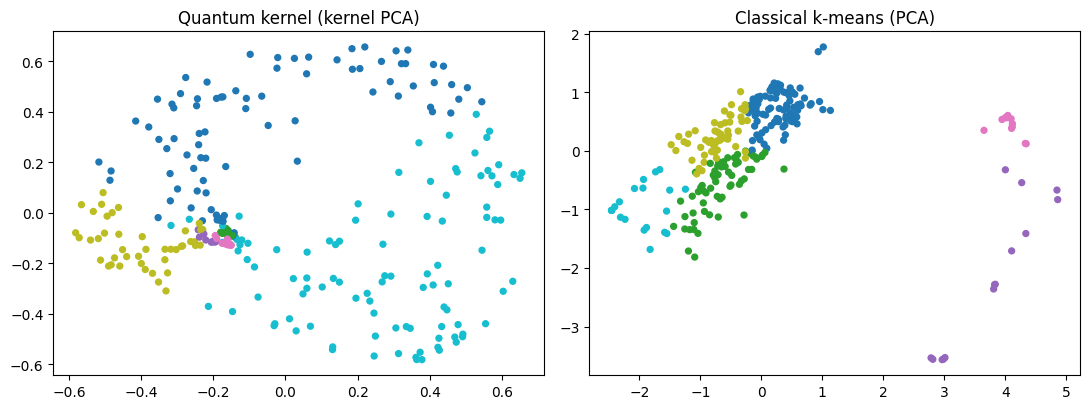

                 log_laplacian_var  mean_lum  std_lum  entropy  fov_coverage  edge_density
cluster_quantum                                                                           
0                             3.67     85.96    21.12     3.98          0.74          0.16
1                             5.45    161.42    46.34     3.68          0.86          0.08
2                             2.71     39.60     9.22     2.74          0.67          0.03
3                             9.79    189.37    63.57     5.15          0.62          0.35
4                             3.43    131.18    19.45     3.43          0.75          0.09
5                             3.74    113.10    21.67     4.17          0.73          0.21


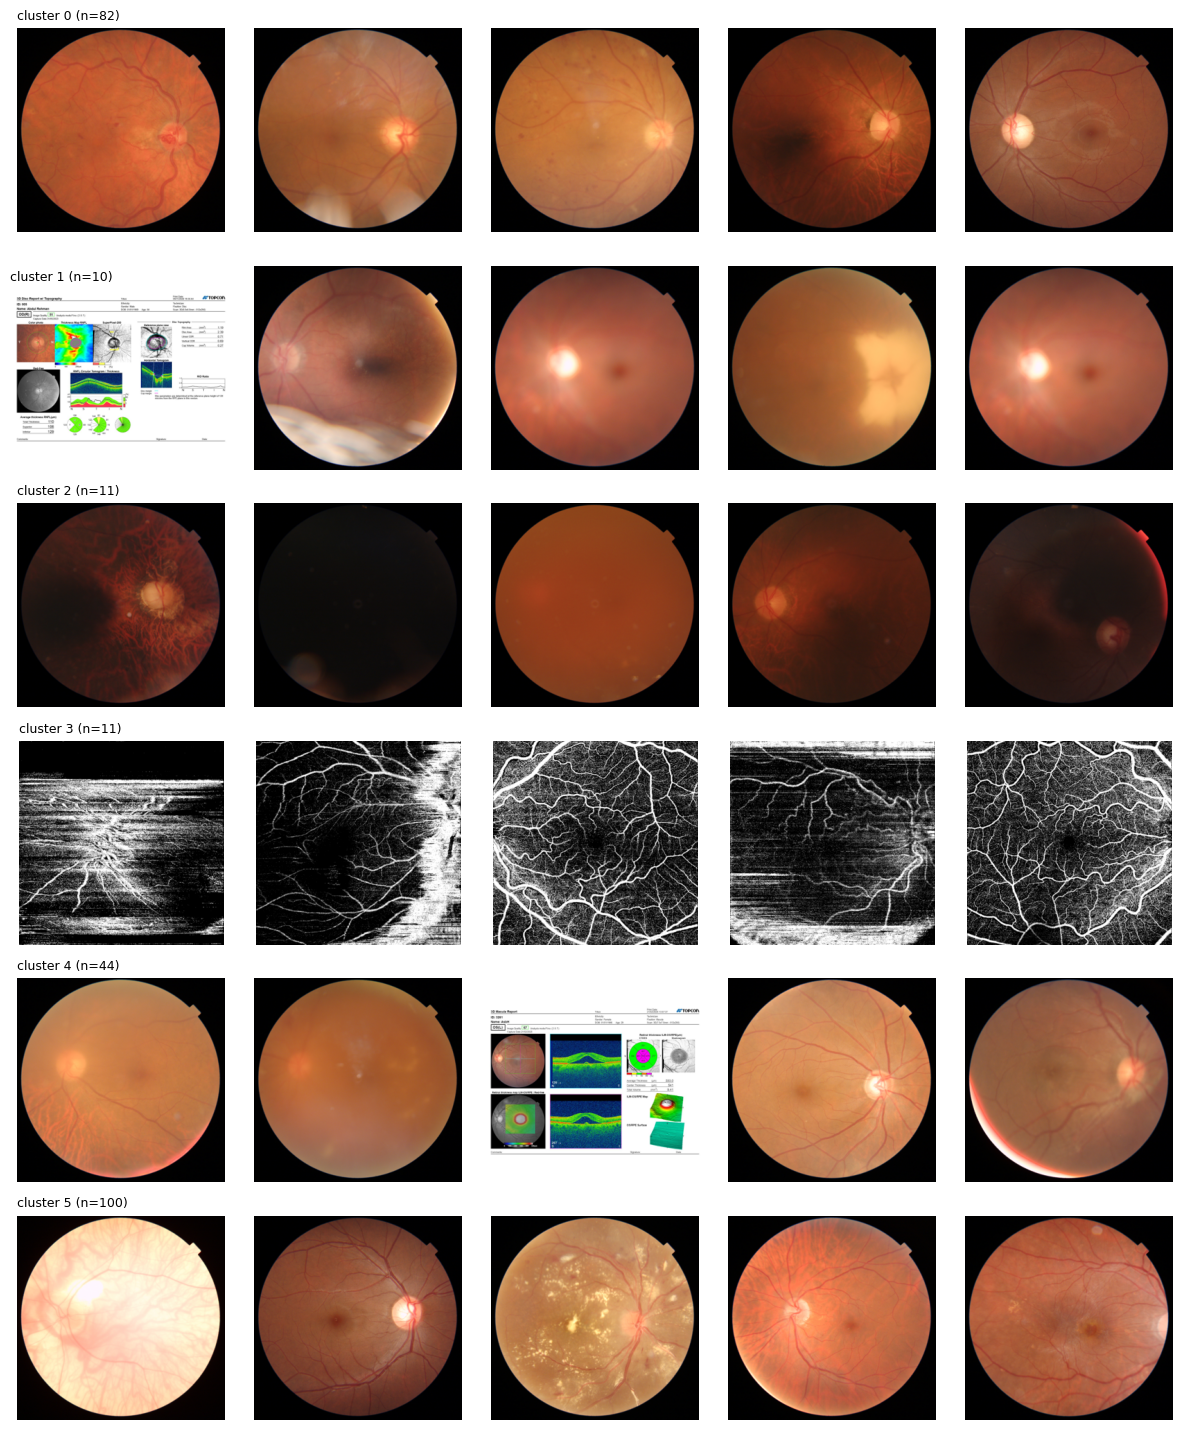


labels.csv not found yet: re-run this cell after the quality labeling is finished.


In [24]:
lab_q = assign["Quantum kernel + spectral"]
out = feat.copy(); out["cluster_quantum"] = lab_q
for n_ in names: out[n_] = assign[n_]
out.to_csv(f"{WORK_DIR}/clusters.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
Z = KernelPCA(2, kernel="precomputed").fit_transform(Kq); ax[0].scatter(Z[:, 0], Z[:, 1], c=lab_q, cmap="tab10", s=18); ax[0].set_title("Quantum kernel (kernel PCA)")
Z = PCA(2).fit_transform(X); ax[1].scatter(Z[:, 0], Z[:, 1], c=assign["Plain k-means (features)"], cmap="tab10", s=18); ax[1].set_title("Classical k-means (PCA)")
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/cluster_maps.png", dpi=150); plt.show()

print(out.groupby("cluster_quantum")[FEATS].mean().round(2).to_string())   # what each cluster means

fig, axs = plt.subplots(K_FIXED, 5, figsize=(12, 2.4 * K_FIXED))
axs = np.atleast_2d(axs)
for c in range(K_FIXED):
    ids = np.where(lab_q == c)[0]; pick_ = rng.choice(ids, min(5, len(ids)), replace=False)
    for j in range(5):
        axs[c, j].axis("off")
        if j < len(pick_):
            im = Image.open(inv.path[pick_[j]]).convert("RGB"); im.thumbnail((300, 300)); axs[c, j].imshow(im)
    axs[c, 0].set_title(f"cluster {c} (n={len(ids)})", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/cluster_examples.png", dpi=120); plt.show()

lab_f = f"{WORK_DIR}/labels.csv"
if os.path.exists(lab_f):
    L = pd.read_csv(lab_f).merge(out[["image_id"] + names], on="image_id")
    print("\nAgreement with usable/not-usable labels (n=%d):" % len(L))
    for n_ in names: print(f"  {n_:34s} ARI={ARI(L.label, L[n_]):.2f}  NMI={NMI(L.label, L[n_]):.2f}")
else:
    print("\nlabels.csv not found yet: re-run this cell after the quality labeling is finished.")